
***Blackjack Example 5.1 — Important Terms***

## 1. Objective

Get as close to 21 as possible without exceeding 21.

## 2. State (S)

The current situation is described by three variables:

$$
S = (\text{Player Sum}, \text{Dealer's Visible Card}, \text{Usable Ace})
$$

- **Player's sum:** 12–21
- **Dealer's visible card:** Ace–10
- **Usable Ace:** Yes or No

## 3. Actions (A)

- **Hit:** Take another card.
- **Stick:** Stop taking cards.

## 4. Policy $(π)$

The policy determines which action the player takes:

- If the player's sum is 20 or 21, **stick**.
- Otherwise, **hit**.

## 5. Dealer's Rule

- If the dealer's sum is below 17, **hit**.
- If the dealer's sum is 17 or above, **stick**.

## 6. Reward (R)

The reward depends on the outcome of the game:

\begin{cases}
+1, & \text{Win}\\
-1, & \text{Loss}\\
0, & \text{Draw}
\end{cases}

## 7. Episode

An episode is one complete game, starting from the initial deal and ending when the outcome is determined.

## 8. Return (G)

The return is the total reward obtained during an episode. In this example, it is the final reward because intermediate rewards are zero and the discount factor is one.

$$
\gamma = 1
$$

Therefore,

$$
G = R_{\text{final}}
$$

## 9. State-Value Function (V(s))

The state-value function represents the expected return from a state when the player follows the given policy.

Monte Carlo estimates the state value by averaging the observed returns:

$$
V(s) =
\frac{\text{Sum of Observed Returns}}
{\text{Number of Visits}}
$$

## 10. Monte Carlo Method

The Monte Carlo method simulates many complete games and estimates each state's value by averaging the returns observed after visiting that state.

## 11. Number of States

The state is represented using three variables:

- 10 possible player sums (12–21)
- 10 possible dealer-visible card values (Ace–10)
- 2 possibilities for a usable Ace (Yes or No)

Therefore, the total number of possible states is:

$$ 10 \times 10 \times 2 = 200 $$

## 12. Experiments

The state values are estimated after simulating:

- **10,000 episodes**
- **500,000 episodes**

The estimated state values are then plotted as graphs to compare the results obtained using different numbers of episodes.


1. Play one Blackjack game

In [12]:

import random
import ipywidgets as widgets
from IPython.display import display
from google.colab import output

output.enable_custom_widget_manager()

# ---------------- GAME LOGIC ----------------

CARD_VALUES = list(range(1, 11))
CARD_PROBS = [1/13] * 9 + [4/13]

def draw_card():
    return random.choices(CARD_VALUES, weights=CARD_PROBS, k=1)[0]

def hand_value(cards):
    total = sum(cards)
    usable_ace = (1 in cards) and (total + 10 <= 21)
    if usable_ace:
        total += 10
    return total, usable_ace

def card_name(card):
    return "A" if card == 1 else str(card)

def cards_html(cards, hidden=False):
    html = ""
    for i, card in enumerate(cards):
        if hidden and i == 1:
            html += """
            <div class="playing-card hidden-card">
                <span>✦</span><small>HIDDEN</small>
            </div>
            """
        else:
            html += f"""
            <div class="playing-card">
                <span>{card_name(card)}</span>
                <small>{'ACE' if card == 1 else 'CARD'}</small>
            </div>
            """
    return html

# ---------------- GAME STATE ----------------

player = []
dealer = []
finished = False
reward = None

# ---------------- UI ----------------

heading = widgets.HTML()
game_display = widgets.HTML()
message = widgets.HTML()

hit_button = widgets.Button(
    description="HIT",
    icon="plus",
    layout=widgets.Layout(width="145px", height="48px")
)

stick_button = widgets.Button(
    description="STICK",
    layout=widgets.Layout(width="145px", height="48px")
)

new_button = widgets.Button(
    description="NEW GAME",
    icon="refresh",
    layout=widgets.Layout(width="165px", height="48px")
)

# ---------------- STYLE ----------------

style = widgets.HTML("""
<style>
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&family=Playfair+Display:wght@600;700;800&display=swap');

.bj-heading {
    font-family: 'Inter', sans-serif;
    padding: 4px 0 12px;
}
.bj-eyebrow {
    font-size: 11px;
    font-weight: 800;
    letter-spacing: 3px;
    color: #9b7130;
}
.bj-main-title {
    font-family: 'Playfair Display', Georgia, serif;
    font-size: 36px;
    line-height: 1.25;
    font-weight: 800;
    color: #174b37 !important;
    margin: 5px 0;
}
.bj-main-title span { color: #bd8732 !important; }
.bj-description {
    color: #53665b;
    font-size: 13px;
    margin-top: 5px;
}

.blackjack-shell {
    font-family: 'Inter', sans-serif;
    background: #111b17;
    color: #f8f6ef;
    border-radius: 18px;
    overflow: hidden;
    border: 1px solid #3c5948;
    box-shadow: 0 12px 30px rgba(20,40,28,.18);
    width: 100%;
    box-sizing: border-box;
}
.bj-header {
    background: linear-gradient(120deg, #183b2c, #24563e);
    padding: 18px 24px;
    border-bottom: 1px solid #52765e;
}
.bj-title {
    font-family: 'Playfair Display', Georgia, serif;
    font-size: 27px;
    font-weight: 800;
    color: #fff7df !important;
}
.bj-title span { color: #ffd879 !important; }
.bj-subtitle {
    color: #d5e6d8;
    font-size: 12px;
    letter-spacing: 1.5px;
    margin-top: 5px;
}

/* NEW: dealer and player side by side */
.bj-table {
    display: grid;
    grid-template-columns: minmax(0, 1fr) minmax(0, 1fr);
    gap: 0;
    background: radial-gradient(ellipse at top, #28694e 0%, #1a4e38 65%, #143b2c 100%);
    padding: 20px 22px;
}
.bj-section {
    padding: 6px 18px 8px 4px;
    min-width: 0;
}
.bj-section + .bj-section {
    border-top: none;
    border-left: 1px solid rgba(255,226,159,.28);
    padding: 6px 4px 8px 22px;
}
.bj-label {
    color: #ffdc8b;
    font-size: 11px;
    font-weight: 800;
    letter-spacing: 2px;
    margin-bottom: 13px;
}
.bj-cards {
    display: flex;
    flex-wrap: wrap;
    gap: 10px;
    min-height: 83px;
    align-items: center;
}
.playing-card {
    flex: 0 0 60px;
    width: 60px;
    height: 82px;
    border-radius: 10px;
    background: #fffdf7;
    box-shadow: 0 5px 10px rgba(0,0,0,.2);
    display: flex;
    flex-direction: column;
    justify-content: center;
    align-items: center;
    border: 1px solid #e3ded0;
    color: #202d26;
    font-weight: 800;
    box-sizing: border-box;
}
.playing-card span { font-size: 27px; line-height: 1.1; }
.playing-card small {
    font-size: 8px;
    letter-spacing: 1px;
    margin-top: 8px;
    color: #697a6d;
}
.hidden-card {
    background: repeating-linear-gradient(45deg, #1c4934, #1c4934 5px, #2c6549 5px, #2c6549 10px);
    color: #ffdc8b;
    border: 2px solid #ffdc8b;
}
.hidden-card small { color: #fff1c9; }
.bj-total {
    color: #f9f8ef;
    font-size: 13px;
    margin-top: 14px;
}
.bj-total strong {
    color: #ffe19a;
    font-size: 22px;
}
.bj-chip {
    display: inline-block;
    padding: 5px 8px;
    margin-top: 6px;
    border-radius: 20px;
    background: #f9e3ad;
    color: #3c321d;
    font-size: 10px;
    font-weight: 800;
}

/* Controls directly under both hands */
.bj-actions {
    background: #17231c;
    padding: 14px 20px;
    border-top: 1px solid #3a5040;
}
.bj-action-label {
    color: #d5e2d7;
    font-family: 'Inter', sans-serif;
    font-size: 11px;
    font-weight: 800;
    letter-spacing: 2px;
    margin-bottom: 10px;
}
.widget-button {
    border: none !important;
    border-radius: 10px !important;
    box-shadow: 0 4px 9px rgba(0,0,0,.15) !important;
    transition: transform .15s ease, filter .15s ease !important;
}
.widget-button:hover:not(:disabled) {
    filter: brightness(1.10) !important;
    transform: translateY(-2px) !important;
}
.widget-button:disabled { opacity: .48 !important; }
.widget-button .widget-label {
    font-family: 'Inter', sans-serif !important;
    font-size: 13px !important;
    font-weight: 800 !important;
    letter-spacing: .7px !important;
}
.bj-tip, .bj-result {
    font-family: 'Inter', sans-serif;
    padding: 13px 16px;
    border-radius: 11px;
    margin-top: 10px;
    font-size: 13px;
    line-height: 1.6;
}
.bj-tip {
    color: #e8f2e9;
    background: #1b3024;
    border: 1px solid #3e6349;
}
.bj-tip strong { color: #ffdc8b; }
.bj-result { font-weight: 500; }
.bj-win {
    background: #e4f6e8;
    border: 1px solid #7dc48c;
    color: #174b2a;
}
.bj-loss {
    background: #ffebeb;
    border: 1px solid #e2a1a1;
    color: #8d2525;
}
.bj-draw {
    background: #fff4d9;
    border: 1px solid #dfc16e;
    color: #75520b;
}

/* On narrow screens, stack the hands so cards don't get squeezed */
@media (max-width: 520px) {
    .bj-table {
        grid-template-columns: minmax(0, 1fr);
        padding: 16px;
    }
    .bj-section {
        padding: 8px 0 18px;
    }
    .bj-section + .bj-section {
        border-left: none;
        border-top: 1px solid rgba(255,226,159,.28);
        padding: 18px 0 8px;
    }
}
</style>
""")

heading.value = """
<div class="bj-heading">
  <div class="bj-eyebrow">CARD TABLE / GAME 01</div>
  <div class="bj-main-title">Blackjack <span>21</span></div>
  <div class="bj-description">
    Beat the dealer. Get close to 21 without going over.
  </div>
</div>
"""

# ---------------- RENDER GAME ----------------

def show_game():
    player_sum, usable_ace = hand_value(player)
    dealer_sum, _ = hand_value(dealer)

    dealer_cards = cards_html(dealer, hidden=not finished)
    dealer_info = (
        f"FINAL TOTAL <strong>{dealer_sum}</strong>"
        if finished else "ONE CARD HIDDEN"
    )

    ace_badge = (
        '<span class="bj-chip">USABLE ACE</span>'
        if usable_ace else ""
    )

    game_display.value = f"""
    <div class="blackjack-shell">
      <div class="bj-header">
        <div class="bj-title">♠ BLACKJACK <span>21</span></div>
        <div class="bj-subtitle">THE CLASSIC CARD GAME</div>
      </div>

      <div class="bj-table">
        <div class="bj-section">
          <div class="bj-label">01 / DEALER</div>
          <div class="bj-cards">{dealer_cards}</div>
          <div class="bj-total">{dealer_info}</div>
        </div>

        <div class="bj-section">
          <div class="bj-label">02 / YOUR HAND</div>
          <div class="bj-cards">{cards_html(player)}</div>
          <div class="bj-total">
            YOUR TOTAL &nbsp; <strong>{player_sum}</strong><br>
            {ace_badge}
          </div>
        </div>
      </div>

      <div class="bj-actions">
        <div class="bj-action-label">MAKE YOUR MOVE</div>
        <div style="color:#d5e2d7;font-size:12px;">
          Hit to draw a card · Stick to end your turn
        </div>
      </div>
    </div>
    """

    hit_button.disabled = finished or player_sum >= 21
    stick_button.disabled = finished

def finish_game(result, explanation):
    global finished, reward
    finished = True
    reward = result

    if result == 1:
        title, css_class, points = "✦ YOU WIN", "bj-win", "+1"
    elif result == -1:
        title, css_class, points = "✕ YOU LOSE", "bj-loss", "−1"
    else:
        title, css_class, points = "＝ DRAW", "bj-draw", "0"

    message.value = f"""
    <div class="bj-result {css_class}">
      <div style="font-size:20px;font-weight:800;margin-bottom:5px;">
        {title} &nbsp; <span style="font-size:14px;">REWARD {points}</span>
      </div>
      <div>{explanation}</div>
    </div>
    """
    show_game()

def start_game():
    global player, dealer, finished, reward

    player = [draw_card(), draw_card()]
    dealer = [draw_card(), draw_card()]
    finished = False
    reward = None
    message.value = ""

    show_game()

    player_sum, _ = hand_value(player)
    dealer_sum, _ = hand_value(dealer)

    player_natural = player_sum == 21
    dealer_natural = dealer_sum == 21

    if player_natural or dealer_natural:
        if player_natural and dealer_natural:
            finish_game(0, "Both player and dealer have a natural blackjack.")
        elif player_natural:
            finish_game(1, "Natural blackjack! You win this round.")
        else:
            finish_game(-1, "The dealer has a natural blackjack.")
    else:
        message.value = """
        <div class="bj-tip">
          <strong>Your turn.</strong> Choose Hit to draw another card,
          or Stick to stand.
        </div>
        """

def hit(_):
    if finished:
        return

    player.append(draw_card())
    player_sum, _ = hand_value(player)

    if player_sum > 21:
        finish_game(-1, "Your total exceeded 21. You busted.")
    elif player_sum == 21:
        stick(None)
    else:
        show_game()
        message.value = f"""
        <div class="bj-tip">
          You drew a card. Your total is
          <strong>{player_sum}</strong>. Hit again or stick?
        </div>
        """

def stick(_):
    if finished:
        return

    dealer_sum, _ = hand_value(dealer)

    while dealer_sum < 17:
        dealer.append(draw_card())
        dealer_sum, _ = hand_value(dealer)

    player_sum, _ = hand_value(player)

    if dealer_sum > 21:
        finish_game(1, "The dealer busted by exceeding 21.")
    elif player_sum > dealer_sum:
        finish_game(1, "Your final total is higher than the dealer's.")
    elif player_sum < dealer_sum:
        finish_game(-1, "The dealer's final total is higher than yours.")
    else:
        finish_game(0, "Both hands have the same total.")

def new_game(_):
    start_game()

# ---------------- BUTTON COLORS ----------------

hit_button.style.button_color = "#2878D0"
hit_button.style.text_color = "#FFFFFF"
hit_button.style.font_weight = "bold"

stick_button.style.button_color = "#7651A8"
stick_button.style.text_color = "#FFFFFF"
stick_button.style.font_weight = "bold"

new_button.style.button_color = "#24764F"
new_button.style.text_color = "#FFFFFF"
new_button.style.font_weight = "bold"

hit_button.on_click(hit)
stick_button.on_click(stick)
new_button.on_click(new_game)

buttons = widgets.HBox(
    [hit_button, stick_button, new_button],
    layout=widgets.Layout(
        gap="12px",
        flex_flow="row wrap",
        margin="10px 0"
    )
)

# ---------------- DISPLAY ----------------

display(style)
display(heading)
display(game_display)
display(buttons)
display(message)

start_game()


HTML(value="\n<style>\n@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&fa…

HTML(value='\n<div class="bj-heading">\n  <div class="bj-eyebrow">CARD TABLE / GAME 01</div>\n  <div class="bj…

HTML(value='')

HTML(value='')

2. Run Monte Carlo experiments and plot state values

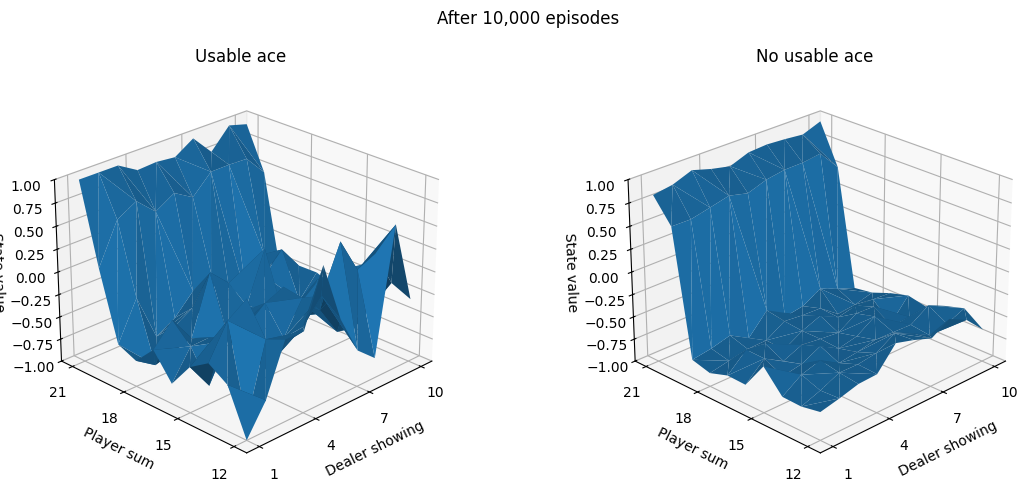

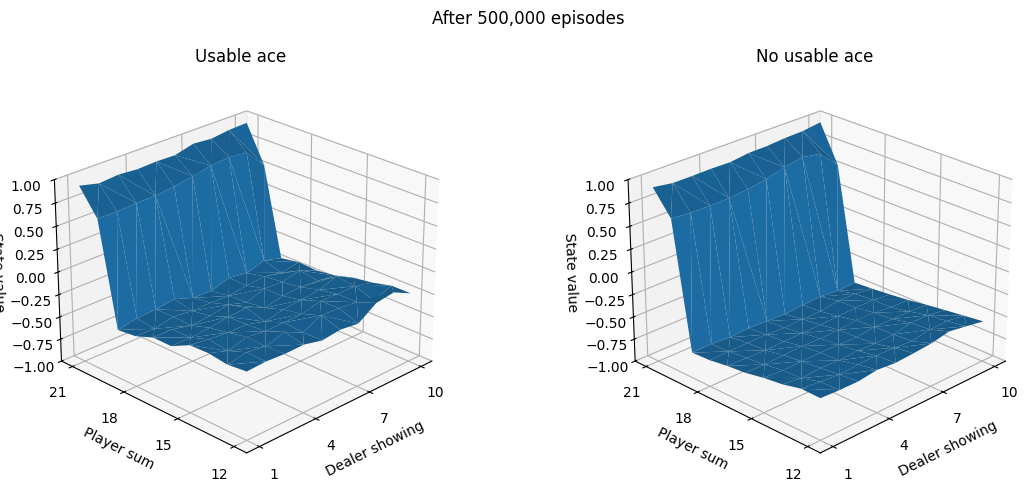

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
CARD_VALUES = np.array([1,2,3,4,5,6,7,8,9,10])
CARD_PROBS = np.array([1/13]*9 + [4/13])  # infinite deck: four 10-valued ranks

def draw_card():
    return int(rng.choice(CARD_VALUES, p=CARD_PROBS))

def hand_value(cards):
    total = sum(cards)
    usable_ace = (1 in cards) and (total + 10 <= 21)
    if usable_ace:
        total += 10
    return total, usable_ace

def play_episode():
    player = [draw_card(), draw_card()]
    dealer = [draw_card(), draw_card()]
    player_sum, _ = hand_value(player)
    dealer_sum, _ = hand_value(dealer)
    dealer_showing = dealer[0]

    # Settle natural blackjack at the start.
    player_natural, dealer_natural = player_sum == 21, dealer_sum == 21
    if player_natural or dealer_natural:
        reward = 0 if player_natural and dealer_natural else (1 if player_natural else -1)
        return reward, []

    visited = []
    while True:
        player_sum, usable_ace = hand_value(player)
        if 12 <= player_sum <= 21:
            visited.append((player_sum, dealer_showing, usable_ace))
        if player_sum >= 20:  # policy sticks on 20 or 21
            break
        player.append(draw_card())
        player_sum, _ = hand_value(player)
        if player_sum > 21:
            return -1, visited

    while True:  # dealer hits below 17
        dealer_sum, _ = hand_value(dealer)
        if dealer_sum >= 17:
            break
        dealer.append(draw_card())
        dealer_sum, _ = hand_value(dealer)
        if dealer_sum > 21:
            return 1, visited

    player_sum, _ = hand_value(player)
    if player_sum > dealer_sum: return 1, visited
    if player_sum < dealer_sum: return -1, visited
    return 0, visited

def mc_prediction(n_episodes):
    returns = {(usable, player, dealer): []
               for usable in [False, True]
               for player in range(12, 22)
               for dealer in range(1, 11)}
    for _ in range(n_episodes):
        reward, states = play_episode()
        for player, dealer, usable in states:
            returns[(usable, player, dealer)].append(reward)
    return {state: np.mean(g) if g else np.nan for state, g in returns.items()}

def plot_values(values, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={"projection": "3d"})
    for ax, usable in zip(axes, [True, False]):
        x, y, z = [], [], []
        for player in range(12, 22):
            for dealer in range(1, 11):
                v = values[(usable, player, dealer)]
                if np.isfinite(v):
                    x.append(dealer); y.append(player); z.append(v)
        ax.plot_trisurf(x, y, z, linewidth=0.15, antialiased=True)
        ax.set_title("Usable ace" if usable else "No usable ace")
        ax.set_xlabel("Dealer showing")
        ax.set_ylabel("Player sum")
        ax.set_zlabel("State value")
        ax.set_zlim(-1, 1)
        ax.set_xticks([1, 4, 7, 10])
        ax.set_yticks([12, 15, 18, 21])
        ax.view_init(elev=25, azim=-135)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

values_10k = mc_prediction(10_000)
plot_values(values_10k, "After 10,000 episodes")
values_500k = mc_prediction(500_000)
plot_values(values_500k, "After 500,000 episodes")
